---

# Praktikum 1: Data Understanding dan Data Preparation

*Persiapan data film dari sembilan file CSV menjadi satu tabel yang bersih dan siap dianalisis.*

---

## Kelompok 19

- 13524001 - Samuelson Dharmawan Tanuraharja
- 13524037 - Nicholas Wise Saragih Sumbayak

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Data Integration**](#4)
5. [**Data Cleaning**](#5)
6. [**Data Transformation**](#6)
7. [**Data Reduction**](#7)


---

# Introduction <a name="1"></a>

---

## Overview

*Anda adalah seorang Data Scientist di Layar Pertama Studio, sebuah rumah produksi film yang sedang menyusun daftar film untuk tahun depan. Tim produksi ingin mengetahui mengapa sebagian film disambut hangat oleh penonton sementara film lain tidak, dan apakah hal itu berkaitan dengan anggaran, genre, durasi, pemeran, atau sutradara.*

*Seluruh informasi tersebut sudah dikumpulkan oleh divisi arsip studio, tetapi tersimpan di sembilan tabel terpisah. Isinya mulai dari data dasar film, genre, kata kunci, perusahaan produksi, dan negara produksi, hingga daftar pemeran dan kru. Beberapa tabel dicatat oleh orang yang berbeda sehingga masih memuat nilai yang hilang, janggal, atau tidak konsisten.*

*Direktur studio meminta Anda menyatukan seluruh tabel menjadi satu tabel analisis yang bersih, dengan satu baris untuk setiap film dan label kelas rating, agar tim data dapat membangun model prediksi penilaian penonton. Anda juga diminta merangkum fitur yang ada agar model tetap ringan.*

## Aim

*Praktikum ini bertujuan melatih seluruh tahap Data Preparation pada CRISP-DM, yaitu Data Understanding, Data Integration, Data Cleaning, Data Transformation, dan Data Reduction. Hasil akhirnya adalah satu tabel dengan satu baris per film, lengkap dengan label `kelas_rating`, yang direduksi menggunakan PCA.*

## Dataset

*Dataset tersedia dalam sembilan file CSV yang saling berelasi dan berisi 4.803 film beserta genre, kata kunci, perusahaan produksi, negara produksi, pemeran, dan kru.*

*Dataset digunakan untuk membentuk satu master table sebagai bahan analisis dan pemodelan.*

**Attributes**

1.  `film.csv`                : Tabel utama, satu baris per film. Kunci utama `id_film`. Berisi `judul`, `judul_asli`, `tanggal_rilis`, `durasi`, `anggaran`, `pendapatan`, `status`, `bahasa_asli`, `popularitas`, `rataan_vote`, `jumlah_vote`, `tagline`, `ringkasan`
2.  `genre.csv`               : Tabel lookup genre (`id_genre`, `nama_genre`)
3.  `film_genre.csv`          : Relasi banyak ke banyak antara film dan genre (`id_film`, `id_genre`)
4.  `kata_kunci.csv`          : Kata kunci tiap film (`id_film`, `id_kata_kunci`, `kata_kunci`)
5.  `perusahaan_produksi.csv` : Perusahaan produksi tiap film (`id_film`, `id_perusahaan`, `nama_perusahaan`)
6.  `negara_produksi.csv`     : Negara produksi tiap film (`id_film`, `kode_negara`)
7.  `negara.csv`              : Tabel lookup negara (`kode_negara`, `nama_negara`, `benua`)
8.  `pemeran.csv`             : Pemeran tiap film (`id_film`, `id_orang`, `nama`, `jenis_kelamin`, `karakter`, `urutan`). `jenis_kelamin` bernilai 0 (tidak diketahui), 1 (perempuan), atau 2 (laki-laki)
9.  `kru.csv`                 : Kru tiap film (`id_film`, `id_orang`, `nama`, `jenis_kelamin`, `departemen`, `jabatan`)

**Target**
 `kelas_rating` : Kelas penilaian film berdasarkan `rataan_vote` (Low, Mid, High), dibentuk pada bagian Data Transformation

## Approach: Data Preparation Pipeline

*Praktikum mengikuti alur Data Preparation dari sembilan tabel mentah hingga fitur numerik hasil PCA. Setiap tahap berisi sel kode dengan bagian kosong yang harus dilengkapi, diikuti Expected Output sebagai pembanding.*

```
9 file CSV
    |
    +-- Data Integration     : agregasi tabel anak, lalu join menjadi 1 baris per film
         |
    +-- Data Cleaning        : nilai nol, missing value, duplikasi, outlier
         |
    +-- Data Transformation  : fitur turunan, label, scaling, encoding
         |
    +-- Data Reduction       : seleksi fitur berbasis korelasi, PCA
```

*Seluruh keputusan pembersihan, misalnya cara mengisi nilai kosong dan batas outlier, sudah ditetapkan pada teks tiap langkah sehingga hasil kode dapat dibandingkan langsung dengan Expected Output.*

## Petunjuk Pengerjaan

*Bagian kode yang harus dilengkapi ditandai dengan `____`. Ganti tanda tersebut dengan ekspresi atau beberapa baris kode yang tepat, lalu jalankan sel dan bandingkan hasilnya dengan Expected Output di bawah sel. Kode di luar bagian kosong tidak perlu diubah.*

*Beberapa langkah menyediakan petunjuk berupa daftar fungsi yang dapat dipakai. Petunjuk disembunyikan secara default dan sebaiknya dibuka hanya setelah Anda mencoba sendiri.*

*Setiap bagian analisis ditutup dengan kotak Insights yang masih kosong. Isi dengan temuan dan interpretasi sendiri berdasarkan output yang dihasilkan. Kotak Pertanyaan berisi pertanyaan konsep yang dijawab dengan alasan sendiri.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Praktikum ini berjalan di CPU sehingga tidak ada pengecekan GPU. Seluruh library yang dibutuhkan umumnya sudah tersedia di Google Colab.

Sel berikut memasang seluruh library yang dipakai pada notebook ini. Baris instalasi diberi komentar secara default dan hanya perlu diaktifkan apabila library belum tersedia di lingkungan kerja.

In [10]:
pip install -q gdown numpy pandas matplotlib scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan pada satu sel.

In [12]:
import os
import random
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

## Settings

Tautan Google Drive kesembilan file CSV, folder tujuan unduhan, batas korelasi, dan target varians PCA dikumpulkan di sini.

In [28]:
class Settings:
    SEED           = 42
    DATA_DIR       = Path('data')
    FROM_DRIVE     = False

    # Ubah sesuai kebutuhan dengan justifikasi
    CORR_THRESHOLD = 0.65
    PCA_VARIANCE   = 0.90

    URLS = {
        'film'               : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Ffilm.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'genre'              : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fgenre.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'film_genre'         : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Ffilm_genre.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'kata_kunci'         : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fkata_kunci.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'perusahaan_produksi': 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fperusahaan_produksi.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'negara_produksi'    : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fnegara_produksi.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'negara'             : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fnegara.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'pemeran'            : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fpemeran.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
        'kru'                : 'https://deepnote.com/workspace/Wise-6f345123-c8e5-40f2-8323-f28be6500d93/project/Nicholas-Wise-Saragih-Sumbayaks-Untitled-project-5c5ec034-d74d-426d-8f2e-e2ddf47a0c98/data%2Fkru.csv?utm_content=5c5ec034-d74d-426d-8f2e-e2ddf47a0c98',
    }

CFG = Settings()
CFG.DATA_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.2f}'.format)

#### Pertanyaan

> Mengapa konfigurasi seperti path data, tautan unduhan, dan parameter lain dikumpulkan dalam satu kelas `Settings`? Menurut Anda, apakah ini cara yang tepat?

> Cara ini merupakan hal yang tepat karena kebutuhan load settings dan penentuan path bukan merupakan bagian dari proses analisis data sehingga seluruh kebutuhan pengaturan akan lebih rapi apabila dikemas dalam satu kelas dan bisa dieksekusi dalam 1 objek kelas sendiri (kalau dalam kode di atas diinstansiasi ke objek CFG).

## Seed Everything

In [20]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

#### Pertanyaan

> Apakah seed perlu ditetapkan pada praktikum ini?

> Seed perlu ditetapkan karena seringkali, banyak fungsi probabilistik/stokastik digunakan dalam Data Science, seperti pada saat modelling. Seed digunakan untuk menjamin "reproducability" (menghasilkan angka yang sama saat dijalankan) dari fungsi-fungsi random/pseudorandom.

## Load Dataset

Kesembilan file CSV diunduh dari Google Drive dengan `gdown`, dibaca menjadi *DataFrame*, lalu ukuran masing-masing ditampilkan.

In [52]:
if CFG.FROM_DRIVE:
    for name, url in CFG.URLS.items():
        gdown.download(url, str(CFG.DATA_DIR / f'{name}.csv'), quiet=True)

tables = {name: pd.read_csv(CFG.DATA_DIR / f'{name}.csv') for name in CFG.URLS}
film, genre, film_genre, kata_kunci, perusahaan_produksi, negara_produksi, negara, pemeran, kru = tables.values()

for name, table in tables.items():
    print(f'{name:<22} {table.shape}')

film                   (4803, 14)
genre                  (20, 2)
film_genre             (12160, 2)
kata_kunci             (36194, 3)
perusahaan_produksi    (13677, 3)
negara_produksi        (6436, 2)
negara                 (184, 3)
pemeran                (106257, 6)
kru                    (129581, 6)


**Expected Output**

```
film                   (4803, 14)
genre                  (20, 2)
film_genre             (12160, 2)
kata_kunci             (36194, 3)
perusahaan_produksi    (13677, 3)
negara_produksi        (6436, 2)
negara                 (184, 3)
pemeran                (106257, 6)
kru                    (129581, 6)
```

---

# Data Understanding <a name="3"></a>

---

Tabel `film` diperiksa lebih dulu karena menjadi dasar seluruh proses integrasi. Pemeriksaan mencakup ukuran, tipe data, *missing value*, nilai nol yang mencurigakan, duplikasi, dan sebaran nilai numerik.

## 3.1 Ukuran dan Tipe Data

Tulis ekspresi yang menampilkan jumlah baris dan kolom serta tipe data tiap kolom.

In [87]:
print(film.shape)
film.dtypes

(4803, 14)


id_film            int64
judul             object
judul_asli        object
tanggal_rilis     object
durasi           float64
anggaran           int64
pendapatan         int64
status            object
bahasa_asli       object
popularitas      float64
rataan_vote      float64
jumlah_vote        int64
tagline           object
ringkasan         object
dtype: object

**Expected Output**

```
(4803, 14)
```

```
id_film            int64
judul                str
judul_asli           str
tanggal_rilis        str
durasi           float64
anggaran           int64
pendapatan         int64
status               str
bahasa_asli          str
popularitas      float64
rataan_vote      float64
jumlah_vote        int64
tagline              str
ringkasan            str
dtype: object
```

## 3.2 Missing Value, Nilai Nol, dan Duplikasi

Pada data film ini, nilai 0 di kolom `anggaran`, `pendapatan`, dan `durasi` tidak berarti anggaran atau durasinya benar-benar nol, melainkan datanya tidak diketahui. Karena itu, selain nilai kosong, jumlah nilai nol juga dihitung.

<details><summary>Petunjuk</summary>

`isna`, `sum`, `duplicated`

</details>

In [179]:
missing = film.isna().sum()
print(missing[missing > 0])

zero_cols = ['anggaran', 'pendapatan', 'durasi']
print(film[zero_cols].eq(0).sum())

tot_dup_judul = film['judul'].duplicated().sum()
print(f'judul ganda   {tot_dup_judul}')

tanggal_rilis      1
durasi             2
tagline          844
ringkasan          3
dtype: int64
anggaran      1037
pendapatan    1427
durasi          35
dtype: int64
judul ganda   3


**Expected Output**

```
tanggal_rilis      1
durasi             2
tagline          844
ringkasan          3
dtype: int64
anggaran      1037
pendapatan    1427
durasi          35
dtype: int64
judul ganda   3
```

## 3.3 Statistik Ringkas

Tampilkan statistik deskriptif untuk kolom `zero_cols` ditambah `popularitas`, `rataan_vote`, dan `jumlah_vote` untuk melihat rentang nilai dan kecenderungan sebarannya.

In [186]:
stat_cols = zero_cols + ['popularitas', 'rataan_vote', 'jumlah_vote']
film[stat_cols].describe()

,anggaran,pendapatan,durasi,popularitas,rataan_vote,jumlah_vote
count,"4,803.00","4,803.00","4,801.00","4,803.00","4,803.00","4,803.00"
mean,"29,045,039.88","82,260,638.65",106.88,21.49,6.09,690.22
std,"40,722,391.26","162,857,100.94",22.61,31.82,1.19,"1,234.59"
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,"790,000.00",0.00,94.00,4.67,5.60,54.00
50%,"15,000,000.00","19,170,001.00",103.00,12.92,6.20,235.00
75%,"40,000,000.00","92,917,187.00",118.00,28.31,6.80,737.00
max,"380,000,000.00","2,787,965,087.00",338.00,875.58,10.00,"13,752.00"


**Expected Output**

```
            anggaran       pendapatan   durasi  popularitas  rataan_vote  jumlah_vote
count       4,803.00         4,803.00 4,801.00     4,803.00     4,803.00     4,803.00
mean   29,045,039.88    82,260,638.65   106.88        21.49         6.09       690.22
std    40,722,391.26   162,857,100.94    22.61        31.82         1.19     1,234.59
min             0.00             0.00     0.00         0.00         0.00         0.00
25%       790,000.00             0.00    94.00         4.67         5.60        54.00
50%    15,000,000.00    19,170,001.00   103.00        12.92         6.20       235.00
75%    40,000,000.00    92,917,187.00   118.00        28.31         6.80       737.00
max   380,000,000.00 2,787,965,087.00   338.00       875.58        10.00    13,752.00
```

#### Insights

> Terdapat 2 missing value pada kolom durasi yang membuat jumlah countnya tidak sama dengan kolom-kolom lainnya. Persebaran data pada kolom pendapatan memiliki value yang paling besar, bisa dilihat dari nilai max dan min nya yang terpaut sangat jauh. Semua kolom di atas memiliki data yang bernilai 0. Kolom pendapatan memiliki paling tidak 25% value yang bernilai 0.

## 3.4 Distribusi Rating dan Pendapatan

Histogram `rataan_vote` dan histogram pendapatan dalam skala logaritmik dibuat berdampingan. Pendapatan bernilai nol diabaikan karena berarti tidak diketahui.

<!-- Use figsize 15, 7 and bins to 50 -->

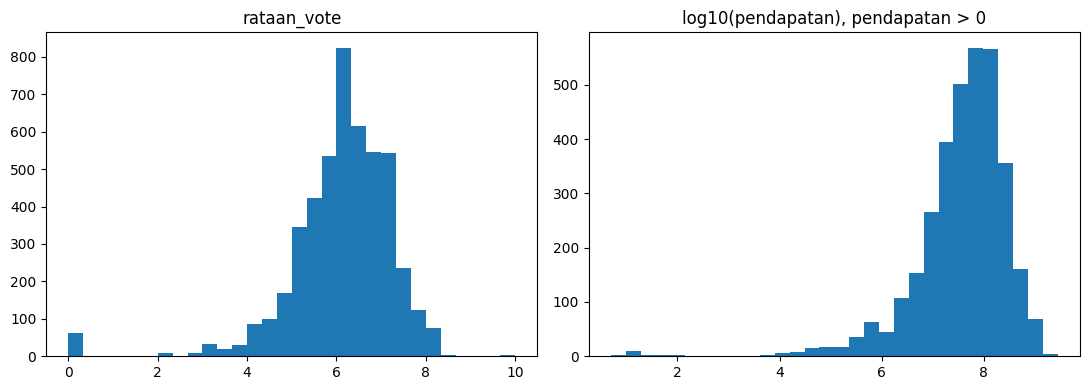

In [220]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(film['rataan_vote'], bins=30)
axes[0].set_title('rataan_vote')

revenue_known = film[film['pendapatan'] > 0]['pendapatan']
axes[1].hist(np.log10(revenue_known), bins=30)
axes[1].set_title('log10(pendapatan), pendapatan > 0')

plt.tight_layout()
plt.show()

**Expected Output**

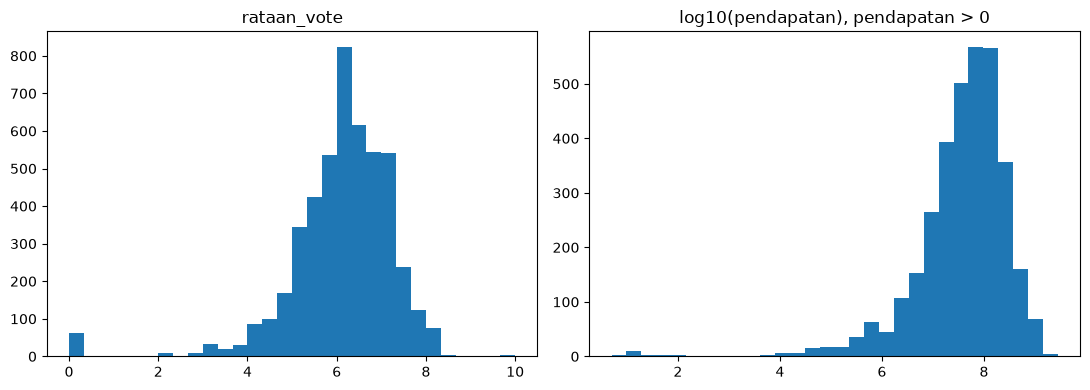

#### Insights

> Tuliskan insight Anda di sini.

## 3.5 Relasi Antar Tabel

Tabel anak (genre, kata kunci, perusahaan, negara, pemeran, kru) berelasi satu ke banyak dengan `film` melalui `id_film`. Rasio baris terhadap film unik menunjukkan seberapa banyak baris yang dimiliki rata-rata satu film.

In [283]:
children = {
    'film_genre': film_genre, 'kata_kunci': kata_kunci, 'perusahaan_produksi': perusahaan_produksi,
    'negara_produksi': negara_produksi, 'pemeran': pemeran, 'kru': kru,
}

relasi = pd.DataFrame({
    'baris': len(film),
    'film_unik': film['id_film'].nunique(),
})
relasi['rata2_per_film'] = relasi['baris'] / len(film)
relasi

ValueError: If using all scalar values, you must pass an index

**Expected Output**

```
                      baris  film_unik  rata2_per_film
film_genre            12160       4775            2.53
kata_kunci            36194       4391            7.54
perusahaan_produksi   13677       4452            2.85
negara_produksi        6436       4629            1.34
pemeran              106257       4760           22.12
kru                  129581       4775           26.98
```

#### Insights

> Tuliskan insight Anda di sini.

---

# Data Integration <a name="4"></a>

---

Tujuan integrasi adalah satu baris per film. Diagram berikut memperlihatkan hubungan antar tabel. Tabel `film` berada di tengah dan setiap tabel lain terhubung melalui `id_film`. Angka 1 dan N pada garis menandai bahwa satu baris di sisi 1 dapat berpasangan dengan banyak baris di sisi N, sedangkan PK adalah kunci utama dan FK adalah kunci asing.

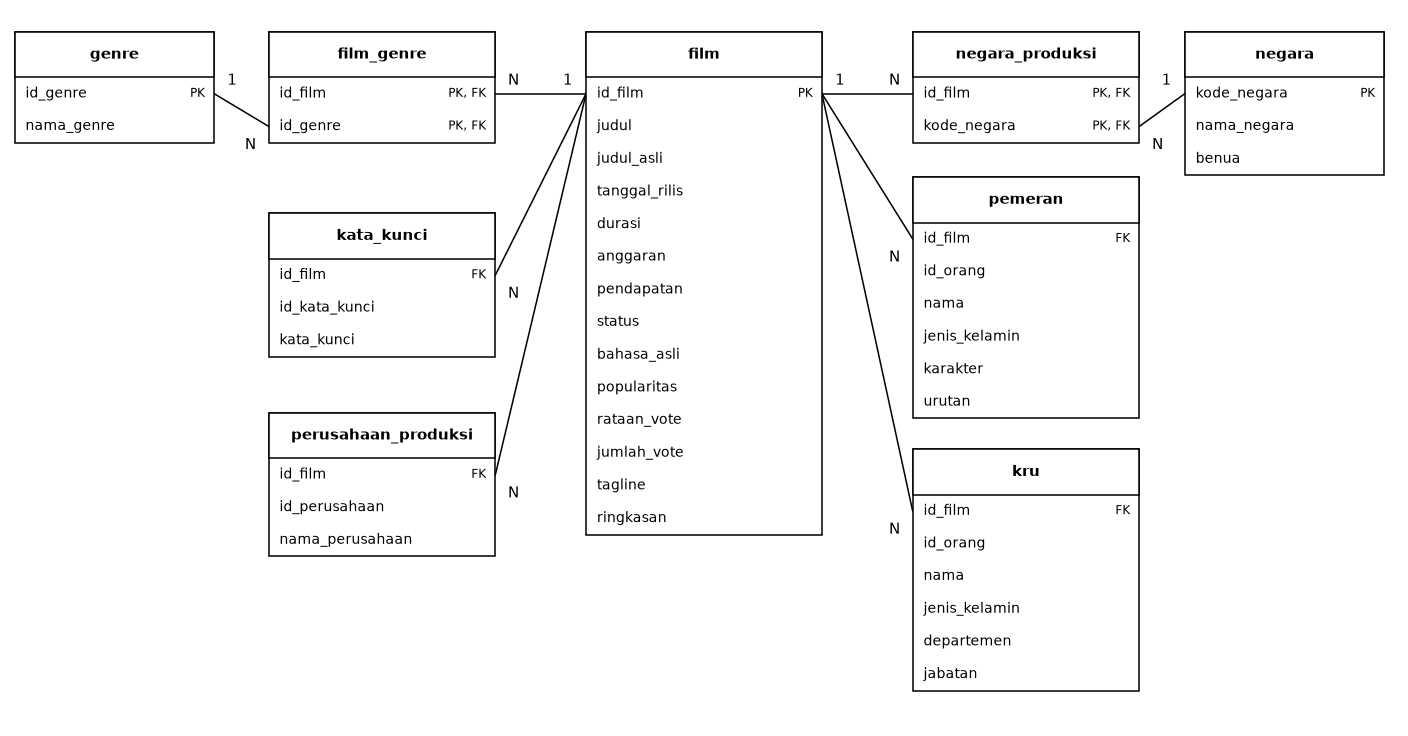

Sel di bawah membandingkan jumlah baris keenam tabel anak dengan jumlah baris apabila tabel-tabel tersebut langsung di-*merge* ke `film`. Strategi yang dipakai selanjutnya adalah mengagregasi setiap tabel anak menjadi satu baris per `id_film`, kemudian menggabungkan hasilnya dengan *join*.

In [257]:
sizes = pd.concat([table.groupby('id_film').size() for table in children.values()], axis=1)
naive_rows = sizes.reindex(film['id_film']).fillna(1).prod(axis=1).sum()
print(f'Jumlah baris keenam tabel anak       {sum(len(table) for table in children.values()):,}')
print(f'Baris jika di-merge langsung ke film {int(naive_rows):,}')

Jumlah baris keenam tabel anak       304,305
Baris jika di-merge langsung ke film 886,258,663


**Expected Output**

```
Jumlah baris keenam tabel anak       304,305
Baris jika di-merge langsung ke film 886,258,663
```

#### Pertanyaan

> Mengapa tabel anak harus diagregasi menjadi satu baris per `id_film` sebelum di-*join*, dan bukan langsung di-*merge* ke `film`?

> Karena jika melakukan join secara naif, banyak join yang dilakukan itu lebih dari seharusnya dan baris yang dihasilkan bisa merupakan baris duplikat. Jika diagregasi menjadi satu baris per id film, dapat dipastikan bahwa mapping ke tabel anak itu dilakukan hanya dari tiap id_film ke atribut yang sesuai di tabel anak tersebut. 

## 4.1 Agregasi Genre

Tabel `film_genre` hanya menyimpan `id_genre`, sehingga perlu digabung dengan `genre` untuk mendapatkan nama genre. Hasil agregasi per film berupa jumlah genre, genre pertama sebagai genre utama, dan daftar seluruh genre yang dipisahkan tanda `|`.

<details><summary>Petunjuk</summary>

`merge`, `groupby`, `size`, `first`, `agg`

</details>

In [280]:
genre_nama = film.merge(film_genre, how='inner', on='id_film').merge(genre, how='inner', on='id_genre')
g = genre_nama.groupby('id_film')['nama_genre']
print(genre_nama)

f_genre = pd.DataFrame({
    'jumlah_genre':,
    'genre_utama':  ,
    'daftar_genre': ____,
})
f_genre.head()

       id_film                                     judul                                judul_asli tanggal_rilis  durasi   anggaran  pendapatan    status bahasa_asli  popularitas  rataan_vote  \
0        19995                                    Avatar                                    Avatar    2009-12-10  162.00  237000000  2787965087  Released          en       150.44         7.20   
1        19995                                    Avatar                                    Avatar    2009-12-10  162.00  237000000  2787965087  Released          en       150.44         7.20   
2        19995                                    Avatar                                    Avatar    2009-12-10  162.00  237000000  2787965087  Released          en       150.44         7.20   
3        19995                                    Avatar                                    Avatar    2009-12-10  162.00  237000000  2787965087  Released          en       150.44         7.20   
4          285  Pirates o

**Expected Output**

```
         jumlah_genre genre_utama                      daftar_genre
id_film                                                            
5                   2       Crime                      Crime|Comedy
11                  3   Adventure  Adventure|Action|Science Fiction
12                  2   Animation                  Animation|Family
13                  3      Comedy              Comedy|Drama|Romance
14                  1       Drama                             Drama
```

## 4.2 Agregasi Kata Kunci dan Perusahaan Produksi

Kata kunci cukup diwakili jumlahnya. Perusahaan produksi diwakili jumlah dan perusahaan pertama yang tercatat sebagai perusahaan utama.

In [258]:
f_kata = ____

p = perusahaan_produksi.groupby('id_film')['nama_perusahaan']
f_prod = pd.DataFrame({
    'jumlah_perusahaan': ____,
    'perusahaan_utama': ____,
})

print(f_kata.head(3))
f_prod.head(3)

NameError: name '____' is not defined

**Expected Output**

```
         jumlah_kata_kunci
id_film                   
5                       10
11                      16
12                      12
```

```
         jumlah_perusahaan         perusahaan_utama
id_film                                            
5                        2            Miramax Films
11                       2                Lucasfilm
12                       1  Pixar Animation Studios
```

## 4.3 Agregasi Negara Produksi

Kode negara pada `negara_produksi` digabung dengan tabel `negara` untuk mendapatkan nama negara dan benua. Jenis *join* yang dipilih harus mempertahankan semua baris `negara_produksi`, termasuk kode negara yang tidak punya benua.

<details><summary>Petunjuk</summary>

`merge` dengan argumen `on` dan `how`, lalu `groupby`

</details>

In [281]:
neg = ____

f_neg = pd.DataFrame({
    'jumlah_negara': ____,
    'negara_utama': ____,
    'benua': ____,
})
f_neg.head()

NameError: name '____' is not defined

**Expected Output**

```
         jumlah_negara              negara_utama          benua
id_film                                                        
5                    1  United States of America  North America
11                   1  United States of America  North America
12                   1  United States of America  North America
13                   1  United States of America  North America
14                   1  United States of America  North America
```

#### Pertanyaan

> Mengapa `negara_produksi` digabung dengan `negara` memakai *left join*, bukan *inner join*?

> Tuliskan jawaban Anda di sini.

## 4.4 Agregasi Pemeran dan Kru

Pemeran diurutkan menurut `urutan` kredit sehingga pemeran pertama menjadi bintang utama. Persentase pemeran perempuan dihitung hanya dari pemeran yang jenis kelaminnya diketahui (1 atau 2). Dari tabel kru diambil sutradara, yaitu baris dengan `jabatan` Director, serta ukuran kru dan jumlah departemen.

<details><summary>Petunjuk</summary>

`sort_values`, `groupby`, `first`, `apply` dengan fungsi `persen_perempuan` yang sudah disediakan, `nunique`, `agg('|'.join)`

</details>

In [ ]:
cast_by_film = pemeran.groupby('id_film')
known_gender = pemeran[pemeran['jenis_kelamin'].isin([1, 2])]
persen_perempuan = lambda s: (s == 1).mean() * 100

f_cast = pd.DataFrame({
    'jumlah_pemeran': ____,
    'bintang_utama': ____,
    'persen_pemeran_perempuan': ____,
})

crew_by_film = kru.groupby('id_film')
f_crew = pd.DataFrame({
    'sutradara': ____,
    'ukuran_kru': ____,
    'jumlah_departemen': ____,
})

print(f_cast.head(3))
f_crew.head(3)

**Expected Output**

```
         jumlah_pemeran  bintang_utama  persen_pemeran_perempuan
id_film                                                         
5                    24       Tim Roth                     63.64
11                  106    Mark Hamill                      6.12
12                   24  Albert Brooks                     23.81
```

```
                                                 sutradara  ukuran_kru  jumlah_departemen
id_film                                                                                  
5        Allison Anders|Alexandre Rockwell|Robert Rodri...          88                 10
11                                            George Lucas          20                  9
12                                          Andrew Stanton         104                  9
```

#### Pertanyaan

> Mengapa persentase pemeran perempuan hanya dihitung dari pemeran yang `jenis_kelamin`-nya 1 atau 2?

> Tuliskan jawaban Anda di sini.

## 4.5 Menggabungkan Semua Tabel

Setiap hasil agregasi digabung ke `film` berdasarkan `id_film` dengan *left join* agar seluruh 4.803 film tetap ada. Film yang tidak punya baris di tabel anak mendapat nilai kosong. Untuk kolom jumlah, kosong berarti nol sehingga langsung diisi 0.

<details><summary>Petunjuk</summary>

`set_index` sudah diterapkan pada `film`. Gunakan perulangan `for` dengan `join`, lalu `fillna` dan `astype`.

</details>

In [ ]:
master = film.set_index('id_film')
____

count_cols = [
    'jumlah_genre', 'jumlah_kata_kunci', 'jumlah_perusahaan', 'jumlah_negara',
    'jumlah_pemeran', 'ukuran_kru', 'jumlah_departemen',
]
master[count_cols] = ____

print(master.shape)
missing = master.isna().sum()
print(missing[missing > 0])

**Expected Output**

```
(4803, 28)
tanggal_rilis                 1
durasi                        2
tagline                     844
ringkasan                     3
genre_utama                  28
daftar_genre                 28
perusahaan_utama            351
negara_utama                174
benua                       180
bintang_utama                43
persen_pemeran_perempuan     86
sutradara                    30
dtype: int64
```

#### Insights

> Tuliskan insight Anda di sini.

---

# Data Cleaning <a name="5"></a>

---

Pembersihan dilakukan pada salinan `master` agar tabel hasil integrasi tetap utuh. Keputusan yang dipakai pada bagian ini ditetapkan sebagai berikut.

- Nilai 0 pada `anggaran`, `pendapatan`, dan `durasi` dianggap tidak diketahui sehingga diubah menjadi NaN.
- `anggaran` dan `pendapatan` di bawah 1.000 USD dianggap tidak masuk akal sehingga diubah menjadi NaN.
- Baris tanpa `tanggal_rilis` dibuang karena tahun dan bulan rilis tidak dapat diturunkan.
- Kolom numerik diisi dengan median, kolom kategorikal berkardinalitas rendah diisi dengan modus.
- *Outlier* ditangani dengan *clipping* berbasis IQR.

`anggaran` dan `pendapatan` sengaja belum diimputasi di sini. Imputasinya dilakukan di dalam *pipeline* pada bagian Data Transformation.

## 5.1 Nilai Nol dan Nilai Tidak Wajar

Nilai nol pada tiga kolom `zero_cols` diganti menjadi NaN, kemudian nilai anggaran dan pendapatan di bawah 1.000 diperlakukan sama.

<details><summary>Petunjuk</summary>

`replace` dengan `np.nan`, dan `df.loc` dengan kondisi boolean untuk mengisi sebagian baris

</details>

In [ ]:
df = master.copy(deep=True)

df[zero_cols] = ____
for col in ['anggaran', 'pendapatan']:
    ____

df[zero_cols].isna().sum()

**Expected Output**

```
anggaran      1069
pendapatan    1449
durasi          37
dtype: int64
```

#### Pertanyaan

> Mengapa `anggaran` dan `pendapatan` yang kosong tidak langsung diimputasi pada tahap pembersihan ini?

> Tuliskan jawaban Anda di sini.

## 5.2 Duplikasi

Duplikasi diperiksa pada indeks (`id_film`) dan pada seluruh kolom. Judul yang sama belum tentu berarti baris ganda, sehingga baris dengan judul kembar ditampilkan untuk diperiksa.

In [ ]:
print('id_film ganda ', ____)
print('baris ganda   ', ____)

kembar = ____
df.loc[kembar, ['judul', 'tanggal_rilis', 'sutradara']].sort_values('judul')

**Expected Output**

```
id_film ganda  0
baris ganda    0
```

```
                   judul tanggal_rilis            sutradara
id_film                                                    
268               Batman    1989-06-23           Tim Burton
2661              Batman    1966-07-30  Leslie H. Martinson
39269    Out of the Blue    1980-05-01        Dennis Hopper
10844    Out of the Blue    2006-10-12       Robert Sarkies
72710           The Host    2013-03-22        Andrew Niccol
1255            The Host    2006-07-27         Bong Joon-ho
```

#### Pertanyaan

> Mengapa duplikasi perlu diperiksa, dan mengapa judul yang sama tidak langsung dihapus?

> Tuliskan jawaban Anda di sini.

## 5.3 Missing Value

Baris tanpa tanggal rilis dibuang. `durasi` diisi dengan median. Kolom kategorikal `genre_utama` dan `benua` diisi dengan modus, sedangkan kolom yang berisi nama orang atau perusahaan diisi dengan teks `Unknown`.

<details><summary>Petunjuk</summary>

`dropna`, `fillna`, `median`, `mode`

</details>

In [ ]:
df = ____

df['durasi'] = ____
for col in ['genre_utama', 'benua']:
    df[col] = ____

name_cols = ['perusahaan_utama', 'negara_utama', 'bintang_utama', 'sutradara']
df[name_cols] = ____

print(df.shape)
missing = df.isna().sum()
print(missing[missing > 0])

**Expected Output**

```
(4802, 28)
```

```
anggaran                    1068
pendapatan                  1448
tagline                      843
ringkasan                      3
daftar_genre                  27
persen_pemeran_perempuan      85
dtype: int64
```

#### Pertanyaan

> Mengapa `durasi` diisi dengan median, kolom kategorikal dengan modus, dan kolom nama dengan teks `Unknown`?

> Tuliskan jawaban Anda di sini.

## 5.4 Outlier

Boxplot `durasi` dan `popularitas` digambarkan lebih dulu untuk melihat sebaran dan titik yang berada jauh dari kelompok data.

<details><summary>Petunjuk</summary>

`ax.boxplot` dengan data tanpa nilai kosong

</details>

<!-- Use figsize 20, 7 -->

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ['durasi', 'popularitas']):
    ____
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

**Expected Output**

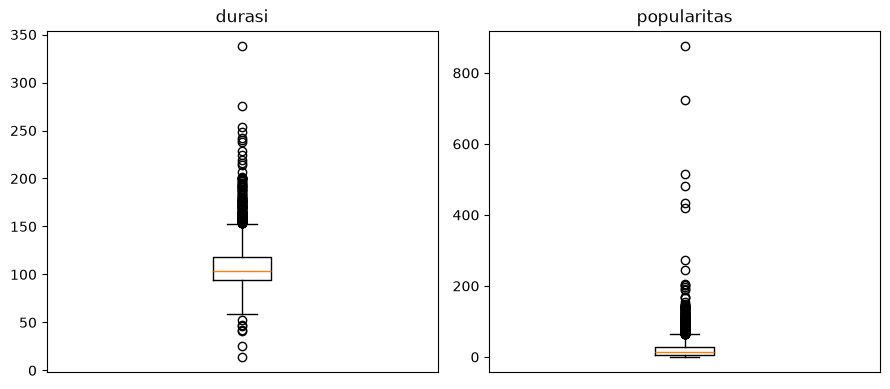

#### Pertanyaan

> Apakah boxplot tepat digunakan untuk memvisualisasikan outlier pada data ini? Mengapa?

> Tuliskan jawaban Anda di sini.

Batas bawah dan batas atas dihitung dengan aturan IQR, yaitu Q1 - 1,5 x IQR dan Q3 + 1,5 x IQR. Nilai di luar batas dipotong ke batas terdekat. Penanganan ini diterapkan pada `durasi` dan `popularitas`.

<details><summary>Petunjuk</summary>

`quantile`, `clip`

</details>

In [ ]:
for col in ['durasi', 'popularitas']:
    ____
    n_outlier = ((df[col] < lower) | (df[col] > upper)).sum()
    df[col] = ____
    print(f'{col:<12} outlier {n_outlier:>4}   batas ({lower:.2f}, {upper:.2f})')

**Expected Output**

```
durasi       outlier  159   batas (58.38, 153.38)
popularitas  outlier  275   batas (-30.82, 63.82)
```

Boxplot yang sama digambarkan kembali setelah pemotongan untuk memastikan titik di luar batas sudah hilang.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ['durasi', 'popularitas']):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

**Expected Output**

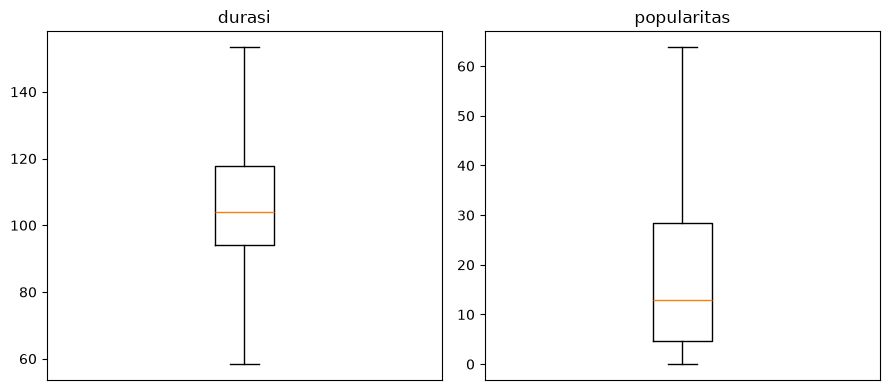

#### Insights

> Tuliskan insight Anda di sini.

---

# Data Transformation <a name="6"></a>

---

Transformasi mengubah tabel bersih menjadi bentuk yang siap dipakai model, yaitu fitur turunan, diskretisasi, label, *scaling*, dan *encoding*.

## 6.1 Fitur Turunan

Tahun, bulan, dan kuartal diturunkan dari `tanggal_rilis`. Laba dihitung dari selisih pendapatan dan anggaran, sedangkan ROI adalah rasio pendapatan terhadap anggaran. Keduanya NaN apabila salah satu nilainya tidak diketahui. `kuartal_rilis` berbentuk teks Q1 sampai Q4.

<details><summary>Petunjuk</summary>

accessor `.dt` dengan `year`, `month`, `quarter`, dan `astype(str)`

</details>

In [ ]:
tgl = pd.to_datetime(df['tanggal_rilis'])
df['tahun'] = ____
df['bulan'] = ____
df['kuartal_rilis'] = ____
df['laba'] = ____
df['roi'] = ____

df[['judul', 'tahun', 'bulan', 'kuartal_rilis', 'laba', 'roi']].head()

**Expected Output**

```
                                            judul  tahun  bulan kuartal_rilis             laba   roi
id_film                                                                                             
19995                                      Avatar   2009     12            Q4 2,550,965,087.00 11.76
285      Pirates of the Caribbean: At World's End   2007      5            Q2   661,000,000.00  3.20
206647                                    Spectre   2015     10            Q4   635,674,609.00  3.59
49026                       The Dark Knight Rises   2012      7            Q3   834,939,099.00  4.34
49529                                 John Carter   2012      3            Q1    24,139,100.00  1.09
```

## 6.2 Diskretisasi Durasi

Durasi dikelompokkan menjadi tiga kategori dengan batas 90 dan 120 menit. Pendek untuk durasi hingga 90 menit, Sedang untuk 91 sampai 120 menit, dan Panjang untuk durasi lebih dari 120 menit. Hasilnya diubah menjadi teks agar dapat di-*encode* nanti.

<details><summary>Petunjuk</summary>

`pd.cut` dengan argumen `bins` dan `labels`, batas atas terakhir `np.inf`

</details>

In [ ]:
df['kategori_durasi'] = ____

df['kategori_durasi'].value_counts()

**Expected Output**

```
kategori_durasi
Sedang     2981
Panjang     988
Pendek      833
Name: count, dtype: int64
```

Histogram `durasi` dengan garis batas 90 dan 120 menit digambarkan untuk memperlihatkan bagaimana nilai kontinu terbagi ke tiga kategori.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(____, bins=30)
for batas in [90, 120]:
    ____
ax.set_xlabel('durasi (menit)')
ax.set_ylabel('jumlah film')
plt.tight_layout()
plt.show()

**Expected Output**

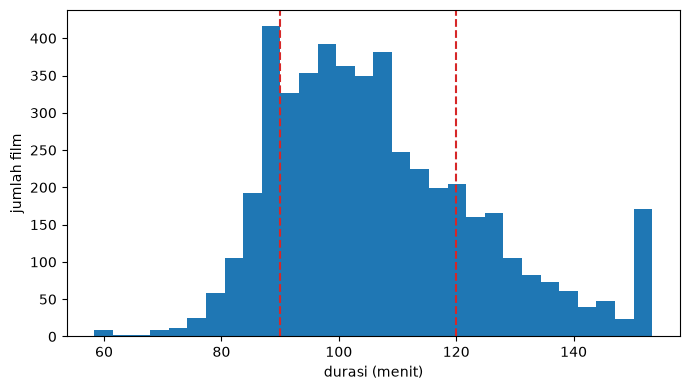

#### Insights

> Tuliskan insight Anda di sini.

## 6.3 Transformasi Logaritmik

Anggaran, pendapatan, popularitas, dan ROI memiliki ekor panjang ke kanan. Transformasi `log1p` menekan pengaruh nilai besar sehingga sebaran lebih simetris. Tabel di bawah membandingkan *skewness* sebelum dan sesudah transformasi.

In [ ]:
skewed_cols = ['anggaran', 'pendapatan', 'popularitas', 'roi']
df_before = df[skewed_cols].copy(deep=True)
skew_before = ____

df[skewed_cols] = ____

pd.DataFrame({'sebelum': skew_before, 'sesudah': df[skewed_cols].skew()})

**Expected Output**

```
             sebelum  sesudah
anggaran        2.22    -1.17
pendapatan      3.88    -1.20
popularitas     1.11    -0.45
roi            49.73     1.71
```

Histogram setiap kolom sebelum dan sesudah transformasi digambarkan berdampingan, kolom kiri untuk sebelum dan kolom kanan untuk sesudah. Nilai kosong dibuang dari histogram dengan `dropna`.

<!-- Use figsize 15, 7 -->

In [ ]:
fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(9, 11))
for i, col in enumerate(skewed_cols):
    axes[i, 0].hist(____, bins=30)
    axes[i, 0].set_title(f'{col} (sebelum)')
    axes[i, 1].hist(____, bins=30)
    axes[i, 1].set_title(f'{col} (sesudah)')
plt.tight_layout()
plt.show()

**Expected Output**

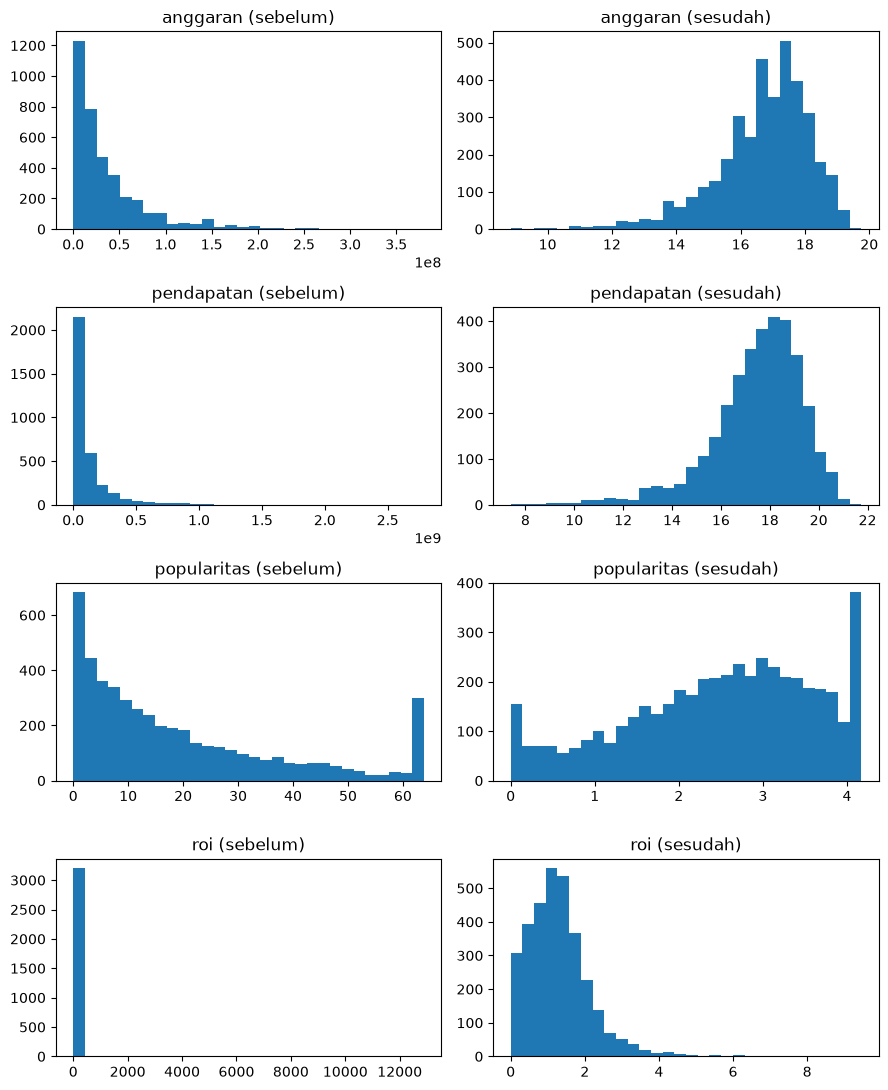

#### Insights

> Tuliskan insight Anda di sini.

## 6.4 Pembentukan Label

Label `kelas_rating` dibentuk dari `rataan_vote` dengan membagi film menjadi tiga kelompok berukuran hampir sama (*tertile*). Film tanpa vote (`jumlah_vote` sama dengan 0) tidak memiliki rating yang bermakna sehingga labelnya kosong dan barisnya dibuang.

<details><summary>Petunjuk</summary>

`where` untuk mengosongkan rating film tanpa vote, lalu `pd.qcut` dengan `labels`

</details>

In [ ]:
rated = ____
df['kelas_rating'] = ____
print(df['kelas_rating'].value_counts(dropna=False))

df = df.dropna(subset=['kelas_rating'])
print(df.shape)

**Expected Output**

```
kelas_rating
Low     1769
High    1533
Mid     1439
NaN       61
Name: count, dtype: int64
(4741, 35)
```

Distribusi kelas hasil pembagian tertile digambarkan sebagai diagram batang berurutan Low, Mid, High.

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
____
ax.set_ylabel('jumlah film')
plt.tight_layout()
plt.show()

**Expected Output**

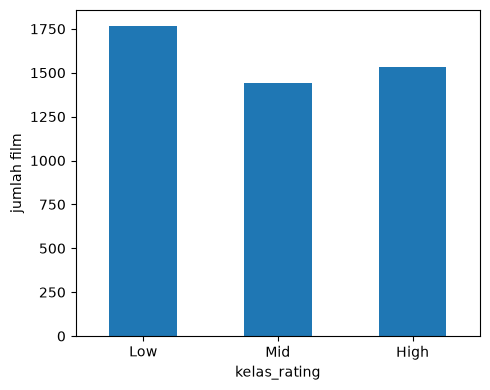

#### Insights

> Tuliskan insight Anda di sini.

## 6.5 Pemisahan Fitur dan Label

Kolom yang bocor dari label, yaitu `rataan_vote` dan `jumlah_vote`, harus dibuang karena `kelas_rating` dibentuk langsung dari rating. Kolom teks dan nama dengan kardinalitas tinggi juga dibuang. Kolom numerik dan kategorikal selanjutnya dipisahkan berdasarkan tipenya. Kolom kategorikal dibagi lagi menjadi ordinal, yaitu `kategori_durasi` yang memiliki urutan Pendek < Sedang < Panjang, dan nominal untuk sisanya.

<details><summary>Petunjuk</summary>

`drop`, `select_dtypes` dengan argumen `include` atau `exclude`

</details>

In [ ]:
leak_cols = ____
text_cols = [
    'judul', 'judul_asli', 'tanggal_rilis', 'tagline', 'ringkasan', 'status', 'daftar_genre',
    'perusahaan_utama', 'negara_utama', 'bintang_utama', 'sutradara',
]

y = ____
X = ____

num_cols = ____
ordinal_cols = ['kategori_durasi']
cat_cols = ____

print(X.shape)
print('numerik    ', num_cols)
print('ordinal    ', ordinal_cols)
print('nominal    ', cat_cols)

**Expected Output**

```
(4741, 21)
numerik     ['durasi', 'anggaran', 'pendapatan', 'popularitas', 'jumlah_genre', 'jumlah_kata_kunci', 'jumlah_perusahaan', 'jumlah_negara', 'jumlah_pemeran', 'persen_pemeran_perempuan', 'ukuran_kru', 'jumlah_departemen', 'tahun', 'bulan', 'laba', 'roi']
ordinal     ['kategori_durasi']
nominal     ['bahasa_asli', 'genre_utama', 'benua', 'kuartal_rilis']
```

#### Pertanyaan

> Mengapa `rataan_vote` dan `jumlah_vote` harus dikeluarkan dari fitur padahal keduanya tersedia di tabel?

> Tuliskan jawaban Anda di sini.

## 6.6 Scaling dan Encoding

Kolom numerik melewati dua langkah, yaitu imputasi dengan median lalu standardisasi. Kolom ordinal diubah dengan *ordinal encoding* sesuai urutan Pendek, Sedang, Panjang sehingga menjadi 0, 1, 2. Kolom nominal diubah dengan *one-hot encoding*, dan kategori yang muncul kurang dari 50 kali digabung menjadi satu kategori `infrequent`. Seluruh langkah dibungkus dalam `ColumnTransformer`.

<details><summary>Petunjuk</summary>

`Pipeline` berisi `SimpleImputer(strategy=...)` dan `StandardScaler()`, `OrdinalEncoder(categories=...)` dengan urutan kategori yang ditulis eksplisit, lalu `ColumnTransformer` dengan daftar `(nama, transformer, kolom)` dan `fit_transform`

</details>

In [ ]:
num_pipe = ____
ord_pipe = ____
cat_pipe = OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False)

preprocess = ____
X_t = ____

print(X_t.shape)
print(preprocess.get_feature_names_out()[:5])
print(np.isnan(X_t).sum())

**Expected Output**

```
(4741, 43)
['num__durasi' 'num__anggaran' 'num__pendapatan' 'num__popularitas'
 'num__jumlah_genre']
0
```

#### Insights

> Tuliskan insight Anda di sini.

---

# Data Reduction <a name="7"></a>

---

Reduksi dilakukan dalam dua tahap. Tahap pertama adalah seleksi fitur numerik dengan membuang fitur yang berkorelasi sangat tinggi dengan fitur lain. Tahap kedua adalah PCA pada fitur numerik yang tersisa.

## 7.1 Seleksi Fitur Berdasarkan Korelasi

Hitung matriks korelasi antar fitur numerik lalu visualisasikan sebagai *heatmap*. Skala warna dibuat simetris dari -1 sampai 1 dengan colormap `coolwarm`, dan label sumbu horizontal maupun vertikal diisi nama fitur.

<details><summary>Petunjuk</summary>

`corr`, `imshow` dengan argumen `cmap`, `vmin`, dan `vmax`, serta `set_yticks`

</details>

In [ ]:
corr = ____

fig, ax = plt.subplots(figsize=(7, 6))
im = ____
ax.set_xticks(range(len(num_cols)), num_cols, rotation=90)
____
fig.colorbar(im)
plt.tight_layout()
plt.show()

**Expected Output**

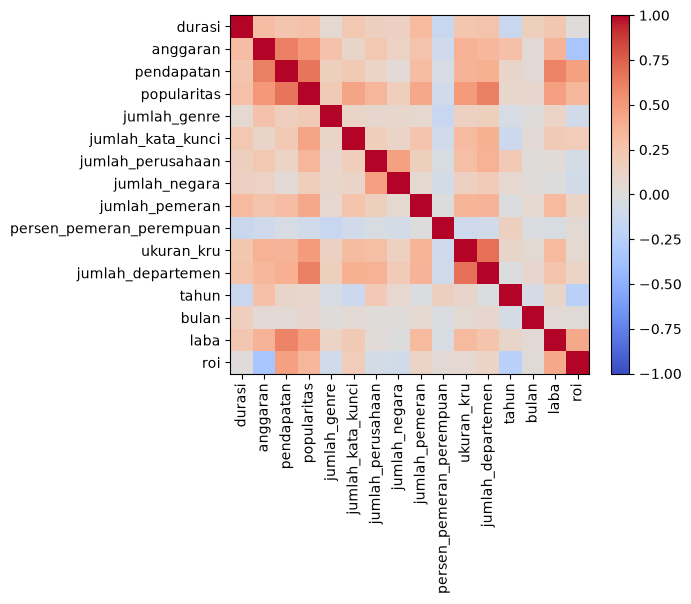

Untuk setiap pasangan fitur dengan korelasi absolut di atas `CFG.CORR_THRESHOLD`, salah satu fitur dibuang. Hanya segitiga atas matriks yang diperiksa agar setiap pasangan tidak dihitung dua kali. Ambang pada `Settings` ditetapkan 0,65, lebih rendah daripada ambang yang umum dipakai, yaitu sekitar 0,8 hingga 0,9.

<details><summary>Petunjuk</summary>

`np.triu` dengan `k=1` membentuk topeng segitiga atas, `where` menerapkannya pada `corr`, lalu `abs` dan `any` per kolom

</details>

In [ ]:
upper = ____
to_drop = ____
num_selected = ____

print('dibuang       ', to_drop)
print('dipertahankan ', len(num_selected), 'fitur numerik')

**Expected Output**

```
dibuang        ['popularitas', 'jumlah_departemen']
dipertahankan  14 fitur numerik
```

#### Insights

> Tuliskan insight Anda di sini.

## 7.2 PCA

Fitur numerik terpilih diimputasi dan distandardisasi dengan `num_pipe`, lalu PCA penuh dijalankan untuk melihat kontribusi varians setiap komponen. Jumlah komponen yang dipakai adalah yang paling sedikit untuk mencapai `CFG.PCA_VARIANCE`.

<details><summary>Petunjuk</summary>

`PCA(...).fit`, atribut `explained_variance_ratio_`, `np.cumsum`, dan `np.argmax` pada kondisi boolean

</details>

In [ ]:
X_num = ____

pca_full = ____
cum_var = ____
n_components = ____

print(f'varians PC1               {pca_full.explained_variance_ratio_[0]:.3f}')
print(f'komponen untuk {CFG.PCA_VARIANCE:.0%} varians  {n_components}')
print(cum_var.round(3))

**Expected Output**

```
varians PC1               0.216
komponen untuk 90% varians  11
[0.216 0.342 0.444 0.532 0.609 0.676 0.737 0.793 0.842 0.884 0.923 0.959
 0.988 1.   ]
```

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
ax.axhline(CFG.PCA_VARIANCE, color='tab:red', linestyle='--')
ax.axvline(n_components, color='tab:red', linestyle='--')
ax.set_xlabel('jumlah komponen')
ax.set_ylabel('varians kumulatif')
plt.tight_layout()
plt.show()

**Expected Output**

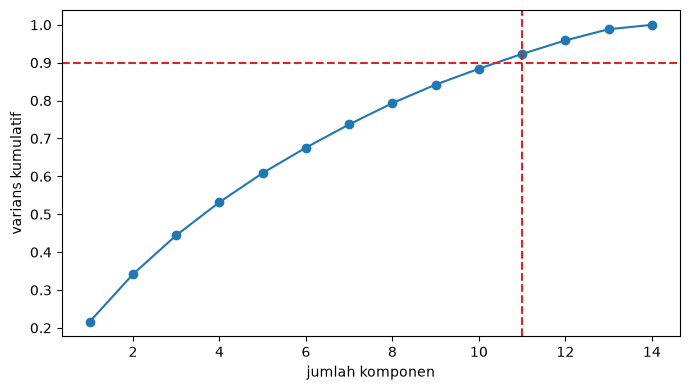

PCA kemudian dijalankan ulang dengan jumlah komponen terpilih. Hasil `X_pca` adalah representasi akhir fitur numerik, dan *loading* menunjukkan fitur yang paling berpengaruh pada PC1.

In [ ]:
pca = ____
X_pca = ____
print(X_num.shape, '->', X_pca.shape)

loadings = ____
____

**Expected Output**

```
(4741, 14) -> (4741, 11)
```

```
                           PC1   PC2
laba                      0.40  0.26
pendapatan                0.40  0.21
ukuran_kru                0.38 -0.10
anggaran                  0.34 -0.29
jumlah_pemeran            0.34  0.06
durasi                    0.29 -0.01
jumlah_kata_kunci         0.27  0.10
jumlah_perusahaan         0.23 -0.40
jumlah_genre              0.17 -0.11
roi                       0.16  0.57
jumlah_negara             0.16 -0.38
persen_pemeran_perempuan -0.10  0.03
bulan                     0.07  0.04
tahun                     0.06 -0.37
```

Dua komponen pertama digambarkan sebagai *scatter plot* dengan warna sesuai `kelas_rating` untuk melihat apakah kelas terpisah.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for label, color in zip(['Low', 'Mid', 'High'], ['tab:red', 'tab:gray', 'tab:blue']):
    mask = (y == label).to_numpy()
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, alpha=0.4, c=color, label=label)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(title='kelas_rating')
plt.tight_layout()
plt.show()

**Expected Output**

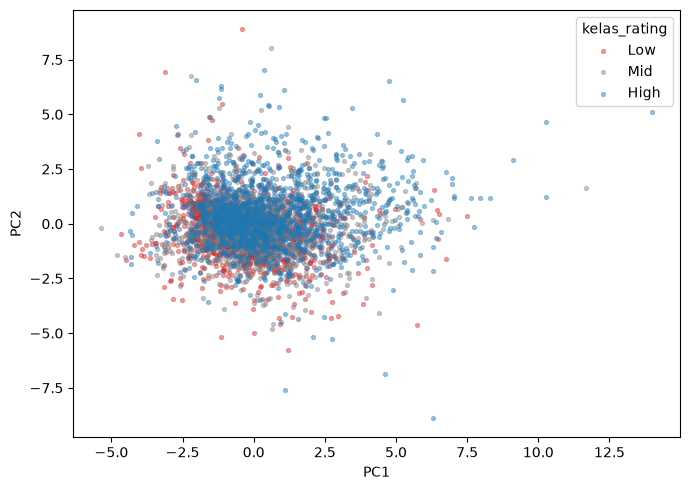

#### Insights

> Tuliskan insight Anda di sini.

## 7.3 Ringkasan

Ukuran data pada setiap tahap dirangkum untuk melihat dampak seluruh proses preparation.

In [ ]:
pd.DataFrame({
    'jumlah_baris': [len(film), len(master), len(df), len(X_pca)],
    'jumlah_kolom': [film.shape[1], master.shape[1] + 1, df.shape[1], X_pca.shape[1]],
}, index=['film (mentah)', 'master (integrasi)', 'df (bersih + label)', 'X_pca (fitur akhir)'])

**Expected Output**

```
                     jumlah_baris  jumlah_kolom
film (mentah)                4803            14
master (integrasi)           4803            29
df (bersih + label)          4741            35
X_pca (fitur akhir)          4741            11
```

#### Insights

> Tuliskan insight Anda di sini.